In [13]:
import pandas as pd
import numpy as np
import math
from scipy import stats as scipy_stats
from scipy.optimize import linprog
from typing import Union, List, Tuple, Callable
import matplotlib.pyplot as plt

In [2]:
def bin_target(df: pd.DataFrame, target_col: str) -> dict:
    """
    Discretise a target column using Scott's rule and return a mapping
    of bin_id -> list of row indices.

    Scott's rule:
        bin_width  h = 3.5 * std(x) * n^(-1/3)
        n_bins       = ceil((max(x) - min(x)) / h)

    Parameters
    ----------
    df         : input DataFrame
    target_col : name of the column to discretise

    Returns
    -------
    dict  {bin_id (int, 0-based): [row_index, ...]}
    """
    x = df[target_col].dropna().values
    n = len(x)

    if n < 2:
        raise ValueError("Need at least 2 non-null values to compute bins.")

    std = np.std(x, ddof=1)          # sample standard deviation
    if std == 0:
        raise ValueError("Target column has zero variance; cannot bin.")

    h       = 3.5 * std * (n ** (-1 / 3))          # Scott's bin width
    n_bins  = max(1, math.ceil((x.max() - x.min()) / h))

    # Cut into n_bins equal-width intervals; labels are 0-based integer bin IDs
    bin_series = pd.cut(
        df[target_col],
        bins=n_bins,
        labels=range(n_bins),
        include_lowest=True
    )

    bin_dict = {}
    for bin_id, group in df.groupby(bin_series, observed=True):
        bin_dict[int(bin_id)] = list(group.index)

    return bin_dict, n_bins

In [3]:
# Sample DataFrame
np.random.seed(42)
df = pd.DataFrame({
    "feature_a": np.random.randn(100),
    "feature_b": np.random.rand(100),
    "target":    np.random.normal(loc=50, scale=15, size=100)
})

bin_map, n_bins = bin_target(df, target_col="target")

print(f"Scott's rule → {n_bins} bins\n")
for bin_id, indices in bin_map.items():
    print(f"  Bin {bin_id:>2d} ({len(indices):>3d} items): {indices[:5]}{'...' if len(indices) > 5 else ''}")

Scott's rule → 9 bins

  Bin  0 (  1 items): [86]
  Bin  1 (  2 items): [45, 60]
  Bin  2 ( 18 items): [6, 13, 17, 20, 23]...
  Bin  3 ( 23 items): [2, 5, 8, 12, 14]...
  Bin  4 ( 32 items): [0, 4, 7, 10, 11]...
  Bin  5 ( 17 items): [1, 9, 15, 26, 27]...
  Bin  6 (  4 items): [58, 72, 76, 90]
  Bin  7 (  2 items): [3, 44]
  Bin  8 (  1 items): [33]


In [4]:
DIST_MAP = {
    "normal":      scipy_stats.norm,
    "gaussian":    scipy_stats.norm,
    "exponential": scipy_stats.expon,
    "beta":        scipy_stats.beta,
    "gamma":       scipy_stats.gamma,
    "uniform":     scipy_stats.uniform,
    "lognormal":   scipy_stats.lognorm,
}

def make_pdf(
    spec: Union[
        Tuple[str, dict],
        List[Tuple[str, dict, float]]
    ]
) -> Callable:
    """
    Single distribution:
        spec = ("normal", {"loc": 0, "scale": 1})

    Mixture (weights are auto-normalised):
        spec = [
            ("normal",      {"loc": 0, "scale": 1},  0.6),
            ("exponential", {"scale": 2},             0.4),
        ]
    """
    if isinstance(spec, tuple):
        name, params = spec
        dist = DIST_MAP[name.lower()]
        return lambda x: dist.pdf(x, **params)

    total_w    = sum(w for _, _, w in spec)
    components = [(DIST_MAP[n.lower()], p, w / total_w) for n, p, w in spec]

    def mixture_pdf(x):
        return sum(w * d.pdf(x, **p) for d, p, w in components)

    return mixture_pdf

In [5]:
def least_cardinality_bin(bin_map: dict) -> Tuple[int, int]:
    """Return (bin_id, cardinality) of the bin with the fewest items."""
    bin_id = min(bin_map, key=lambda b: len(bin_map[b]))
    return bin_id, len(bin_map[bin_id])


def _bin_centers(df: pd.DataFrame, target_col: str, n_bins: int) -> np.ndarray:
    """Midpoint of each equal-width bin over the target column range."""
    lo, hi = df[target_col].min(), df[target_col].max()
    edges  = np.linspace(lo, hi, n_bins + 1)
    return (edges[:-1] + edges[1:]) / 2

In [ ]:
EPS = 1e-9   # prevents bins from collapsing to 0 when c = 0

def find_sampling_plan(
    bin_map:       dict,
    df:            pd.DataFrame,
    target_col:    str,
    n_bins:        int,
    pdf:           Callable,
    min_total_pct: float = 0.0,
) -> Tuple[dict, List[int], bool]:
    """
    For c = 0, 1, ..., capacity(anchor bin), derive required counts for every
    bin as round((c + eps) * pdf_i / pdf_anchor).  For bins that were the
    anchor in an earlier (failed) round, this value is clamped to the bin's
    full capacity -- their requirement is always considered satisfied and
    does not affect feasibility.  Collect every level where the remaining
    (never-clamped) bins fit within their capacities, then pick the one whose
    total is the smallest value >= min_total_pct * len(df).

    If no c yields a feasible level for the current anchor (the bin with the
    lowest pdf among bins not yet used as an anchor), mark that bin as seen
    and retry with the next lowest-pdf bin as the anchor.  Repeat until a
    feasible level is found or every bin has been used as an anchor.

    Returns
    -------
    required  : {bin_id: required_count} for the chosen level (empty if infeasible)
    peak_bins : bin_ids at the distribution peak
    feasible  : True iff a valid level meeting the total constraint exists
    """
    centers  = _bin_centers(df, target_col, n_bins)
    bin_ids  = sorted(bin_map.keys())
    pdf_vals = {bid: pdf(centers[bid]) for bid in bin_ids}

    peak_pdf  = max(pdf_vals.values())
    peak_bins = [bid for bid in bin_ids if np.isclose(pdf_vals[bid], peak_pdf)]

    min_total = round(min_total_pct * len(df))

    seen    = set()  # bins that were anchors in earlier, infeasible rounds
    anchors = sorted(bin_ids, key=lambda b: pdf_vals[b])

    for anchor in anchors:
        anchor_pdf = pdf_vals[anchor]
        anchor_cap = len(bin_map[anchor])

        feasible_levels = []
        for c in range(anchor_cap + 1):
            required = {}
            for bid in bin_ids:
                val = round((c + EPS) * pdf_vals[bid] / anchor_pdf)
                required[bid] = min(val, len(bin_map[bid])) if bid in seen else val
            if all(required[bid] <= len(bin_map[bid]) for bid in bin_ids):
                feasible_levels.append((sum(required.values()), required))

        if feasible_levels:
            candidates = [(total, req) for total, req in feasible_levels if total >= min_total]
            if not candidates:
                return {}, peak_bins, False
            _, best_required = min(candidates, key=lambda x: x[0])
            return best_required, peak_bins, True

        seen.add(anchor)

    # every bin used as an anchor -- the only possible level is "take everything"
    required = {bid: len(bin_map[bid]) for bid in bin_ids}
    if sum(required.values()) >= min_total:
        return required, peak_bins, True
    return {}, peak_bins, False

In [7]:
def sanity_check(
    bin_map:       dict,
    df:            pd.DataFrame,
    required:      dict,
    min_total_pct: float = 0.0,
) -> pd.DataFrame:
    """
    Compare required vs available cardinality per bin using a pre-computed
    required dict from find_sampling_plan.  Appends a TOTAL row that checks
    the minimum total cardinality constraint (min_total_pct * len(df)).
    """
    min_total = round(min_total_pct * len(df))

    rows = []
    for bid, req in sorted(required.items()):
        available = len(bin_map[bid])
        rows.append({
            "bin_id":     bid,
            "available":  available,
            "required":   req,
            "sufficient": available >= req,
        })

    report    = pd.DataFrame(rows)
    total_req = report["required"].sum()
    total_avl = report["available"].sum()

    report = pd.concat([report, pd.DataFrame([{
        "bin_id":     "TOTAL",
        "available":  total_avl,
        "required":   total_req,
        "sufficient": total_req >= min_total,
    }])], ignore_index=True)

    bins_ok  = report.iloc[:-1]["sufficient"].all()
    total_ok = total_req >= min_total
    status   = "PASSED ✓" if (bins_ok and total_ok) else "FAILED ✗"
    print(f"Sanity check {status}")
    print(f"  Bin capacities : {report.iloc[:-1]['sufficient'].sum()}/{len(report)-1} sufficient")
    print(f"  Total samples  : {total_req} / {len(df)} rows  "
          f"({100*total_req/len(df):.1f}%,  min required: {min_total_pct*100:.0f}% = {min_total}) "
          f"{'✓' if total_ok else '✗'}")
    return report

In [9]:
np.random.seed(42)
df = pd.DataFrame({
    "feature_a": np.random.randn(1500),
    "feature_b": np.random.randn(1500),
    "feature_c": np.random.randn(1500),
    "target":    np.random.normal(loc=50, scale=15, size=1500),
})
bin_map, n_bins = bin_target(df, "target")
pdf = make_pdf(("gaussian", {"loc": 50, "scale": 15}))

lc_bin, lc_count = least_cardinality_bin(bin_map)
print(f"Least-cardinality bin: {lc_bin}  (n={lc_count})  |  Total rows: {len(df)}\n")

# case 1: achievable (40% of 500 = 200 rows)
PCT = 0.10
required, peak_bins, ok = find_sampling_plan(bin_map, df, "target", n_bins, pdf, min_total_pct=PCT)
print(f"[min_total_pct={PCT:.0%}]  feasible={ok}  peak_bins={peak_bins}\n")
report = sanity_check(bin_map, df, required, min_total_pct=PCT)
display(report)

# # case 2: infeasible (99% of 500 = 495 rows)
# print("\n── Infeasible min_total_pct ──")
# PCT_BIG = 0.99
# _, _, ok2 = find_sampling_plan(bin_map, df, "target", n_bins, pdf, min_total_pct=PCT_BIG)
# print(f"[min_total_pct={PCT_BIG:.0%}]  feasible={ok2}")

# # case 3: bimodal mixture at 50% coverage
# print("\n── Bimodal mixture ──")
# pdf_mix = make_pdf([
#     ("normal", {"loc": 35, "scale": 8},  0.5),
#     ("normal", {"loc": 65, "scale": 8},  0.5),
# ])
# required_mix, peak_bins_mix, ok_mix = find_sampling_plan(
#     bin_map, df, "target", n_bins, pdf_mix, min_total_pct=0.50
# )
# print(f"[min_total_pct=50%]  feasible={ok_mix}  peak_bins={peak_bins_mix}\n")
# report_mix = sanity_check(bin_map, df, required_mix, min_total_pct=0.50)
# display(report_mix)

Least-cardinality bin: 0  (n=4)  |  Total rows: 1500

[min_total_pct=10%]  feasible=True  peak_bins=[10]

Sanity check PASSED ✓
  Bin capacities : 21/21 sufficient
  Total samples  : 814 / 1500 rows  (54.3%,  min required: 10% = 150) ✓


,bin_id,available,required,sufficient
0,0,4,1,True
1,1,5,2,True
2,2,10,5,True
3,3,24,10,True
4,4,34,18,True
5,5,59,30,True
6,6,75,46,True
7,7,120,63,True
8,8,160,80,True
9,9,166,92,True


In [ ]:
def solve_island_lp_dual(
    order:          np.ndarray,
    bin_ids_sorted: np.ndarray,
    required:       dict,
):
    """
    Identical pipeline to solve_island_lp (iterative McCormick variable
    fixing) but at each round solves the dual LP instead of the primal.
    The primal solution is recovered as z* = -res.ineqlin.marginals.
    See the derivation cell above for the dual formulation.
    """
    n = len(order)
    fixed_x = {}

    for _ in range(n):
        fixed_w = {}
        for i in range(n):
            xi1_known = (i + 1 >= n) or (i + 1 in fixed_x)
            if i in fixed_x and xi1_known:
                xi1_val    = fixed_x.get(i + 1, 0) if i + 1 < n else 0
                fixed_w[i] = fixed_x[i] * xi1_val

        free_x = [i for i in range(n) if i not in fixed_x]
        free_w = [i for i in range(n) if i not in fixed_w]
        n_fx, n_fw = len(free_x), len(free_w)
        n_vars     = n_fx + n_fw

        x_col = {pos: col        for col, pos in enumerate(free_x)}
        w_col = {i:   n_fx + col for col, i   in enumerate(free_w)}

        c = np.concatenate([np.ones(n_fx), -np.ones(n_fw)])

        ineq_rows, b_ub_list = [], []
        for i in range(n):
            if i in fixed_w:
                continue
            xi_free  = i not in fixed_x
            xi_val   = fixed_x.get(i, 0)
            xi1_free = (i + 1 < n) and (i + 1 not in fixed_x)
            xi1_val  = fixed_x.get(i + 1, 0) if i + 1 < n else 0
            wi       = w_col[i]
            row = np.zeros(n_vars); rhs = 1.0
            if xi_free:  row[x_col[i]]       += 1
            else:        rhs                 -= xi_val
            if xi1_free: row[x_col[i + 1]]   += 1
            else:        rhs                 -= xi1_val
            row[wi] = -1
            ineq_rows.append(row); b_ub_list.append(rhs)
            row = np.zeros(n_vars); rhs = 0.0
            row[wi] = 1
            if xi_free:  row[x_col[i]] -= 1
            else:        rhs           += xi_val
            ineq_rows.append(row); b_ub_list.append(rhs)
            row = np.zeros(n_vars); rhs = 0.0
            row[wi] = 1
            if xi1_free: row[x_col[i + 1]] -= 1
            else:        rhs               += xi1_val
            ineq_rows.append(row); b_ub_list.append(rhs)

        A_ub = np.array(ineq_rows) if ineq_rows else np.empty((0, n_vars))
        b_ub = np.array(b_ub_list) if b_ub_list else np.empty(0)

        eq_rows, b_eq_list = [], []
        for bin_id, b_k in required.items():
            row = np.zeros(n_vars); rhs = float(b_k)
            for pos in np.where(bin_ids_sorted == bin_id)[0]:
                if pos in fixed_x:
                    rhs -= fixed_x[pos]
                else:
                    row[x_col[pos]] = 1
            eq_rows.append(row); b_eq_list.append(rhs)
        A_eq = np.array(eq_rows)
        b_eq = np.array(b_eq_list)

        # --- build dual LP ---
        n_lam = A_ub.shape[0]   # λ: one per McCormick ineq
        n_nu  = A_eq.shape[0]   # μ: one per bin-quota eq
        n_p   = n_vars           # p: one per primal variable (upper bound z ≤ 1)

        c_dual = np.concatenate([b_ub, b_eq, np.ones(n_p)])

        A_lam  = -A_ub.T if n_lam > 0 else np.zeros((n_vars, 0))
        A_dual = np.hstack([A_lam, -A_eq.T, -np.eye(n_vars)])
        b_dual = c   # primal objective vector becomes dual RHS

        dual_bounds = (
            [(0, None)]    * n_lam +   # λ ≥ 0
            [(None, None)] * n_nu  +   # μ unrestricted
            [(0, None)]    * n_p       # p ≥ 0
        )

        res = linprog(c_dual, A_ub=A_dual, b_ub=b_dual,
                      bounds=dual_bounds, method="highs")
        if not res.success:
            return None, None

        # primal z* = −shadow prices of the dual's n_vars inequality constraints
        z_star      = -res.ineqlin.marginals
        x_free_vals = z_star[:n_fx]

        best_pos, best_dist, best_val = None, None, None
        for col, pos in enumerate(free_x):
            v = x_free_vals[col]
            d1, d0 = abs(v - 1), abs(v)
            d, val = (d1, 1) if d1 <= d0 else (d0, 0)
            if best_dist is None or d < best_dist:
                best_pos, best_dist, best_val = pos, d, val
        fixed_x[best_pos] = best_val

    # all n variables fixed — verify and return
    x_full    = np.array([fixed_x[i] for i in range(n)])
    selection = x_full.astype(int)
    valid = all(
        int(sum(selection[pos]
                for pos in np.where(bin_ids_sorted == bin_id)[0])) == b_k
        for bin_id, b_k in required.items()
    )
    if not valid:
        return None, None
    mdl = int(sum(
        selection[i] * (1 - (selection[i + 1] if i + 1 < n else 0))
        for i in range(n)
    ))
    return selection, mdl

## Dual of the McCormick LP

**Primal** (each iteration, over free variables $z = [x_\text{free};\, w_\text{free}]$):

$$\min\; c^\top z \quad \text{s.t.}\quad A_\text{ub}\,z \le b_\text{ub},\quad A_\text{eq}\,z = b_\text{eq},\quad 0 \le z \le 1$$

Form the Lagrangian with multipliers $\lambda \ge 0$ (McCormick inequalities),
$\mu$ unrestricted (bin-quota equalities), $\nu \ge 0$ (lower bounds $z \ge 0$),
$p \ge 0$ (upper bounds $z \le 1$):

$$L = c^\top z + \lambda^\top(A_\text{ub}\,z - b_\text{ub}) + \mu^\top(A_\text{eq}\,z - b_\text{eq}) - \nu^\top z + p^\top(z - 1)$$

Stationarity $\partial L/\partial z = 0$ gives $\nu = c + A_\text{ub}^\top\lambda + A_\text{eq}^\top\mu + p$.
Since $\nu \ge 0$, the dual feasibility constraint is

$$A_\text{ub}^\top\lambda + A_\text{eq}^\top\mu + p \;\ge\; -c$$

The dual objective (z terms vanish) is $g = -\lambda^\top b_\text{ub} - \mu^\top b_\text{eq} - p^\top\mathbf{1}$.

**Dual** (written as minimisation for `scipy.optimize.linprog`):

$$\min\; b_\text{ub}^\top\lambda + b_\text{eq}^\top\mu + \mathbf{1}^\top p$$

$$\text{s.t.}\quad \bigl[-A_\text{ub}^\top \;\big|\; -A_\text{eq}^\top \;\big|\; -I\bigr]\,[\lambda;\,\mu;\,p] \;\le\; c \qquad (n_\text{vars}\text{ constraints})$$

$$\lambda \ge 0,\quad \mu \text{ unrestricted},\quad p \ge 0$$

**Primal recovery** via strong duality — the shadow prices of the dual's $n_\text{vars}$ inequality constraints (whose RHS is $c$) equal $-z^*$:

$$z^*_j \;=\; -\,\frac{\partial(\text{dual obj}^*)}{\partial c_j} \;=\; -\,\texttt{res.ineqlin.marginals}[j]$$

In [ ]:
def select_subsets(
    df:        pd.DataFrame,
    bin_map:   dict,
    required:  dict,
    n_subsets: int,
    columns:   List[str] = None,
) -> pd.DataFrame:
    """
    For every candidate column, sort the dataset ascending by that column and
    solve the island-minimisation LP for the row selection that satisfies the
    per-bin quotas (`required`) with minimal MDL (number of contiguous islands
    of selected rows).  Returns the n_subsets simplest (lowest-MDL) results.

    Returns a DataFrame: column | mdl | selected_indices
    """
    if columns is None:
        columns = list(df.columns)

    bin_of_index = {idx: bid for bid, idxs in bin_map.items() for idx in idxs}

    results = []
    for col in columns:
        order = df[col].sort_values(kind="mergesort").index.to_numpy()
        bin_ids_sorted = np.array([bin_of_index[idx] for idx in order])

        selection, mdl = solve_island_lp_dual(order, bin_ids_sorted, required)
        if selection is None:
            continue

        results.append({
            "column":           col,
            "mdl":              mdl,
            "selected_indices": order[selection.astype(bool)].tolist(),
        })

    report = pd.DataFrame(results).sort_values("mdl", kind="mergesort").reset_index(drop=True)
    return report.head(n_subsets)

In [16]:
N_SUBSETS = 3
subset_report = select_subsets(df, bin_map, required, n_subsets=N_SUBSETS)

print(f"Top {N_SUBSETS} simplest subsets (lowest MDL = fewest islands of selected rows):\n")
for _, row in subset_report.iterrows():
    idxs = row["selected_indices"]
    print(f"  Column '{row['column']}'  →  MDL = {row['mdl']}  "
          f"({len(idxs)} rows selected)  e.g. {idxs[:8]}{'...' if len(idxs) > 8 else ''}")

display(subset_report)

Top 3 simplest subsets (lowest MDL = fewest islands of selected rows):

  Column 'feature_a'  →  MDL = 9  (814 rows selected)  e.g. [1461, 1245, 684, 35, 325, 533, 1328, 1255]...
  Column 'feature_c'  →  MDL = 11  (814 rows selected)  e.g. [1207, 1033, 17, 1006, 1145, 481, 155, 1042]...
  Column 'feature_b'  →  MDL = 12  (814 rows selected)  e.g. [1380, 1017, 684, 1107, 212, 844, 316, 456]...


,column,mdl,selected_indices
0,feature_a,9,"[1461, 1245, 684, 35, 325, 533, 1328, 1255, 24..."
1,feature_c,11,"[1207, 1033, 17, 1006, 1145, 481, 155, 1042, 9..."
2,feature_b,12,"[1380, 1017, 684, 1107, 212, 844, 316, 456, 13..."


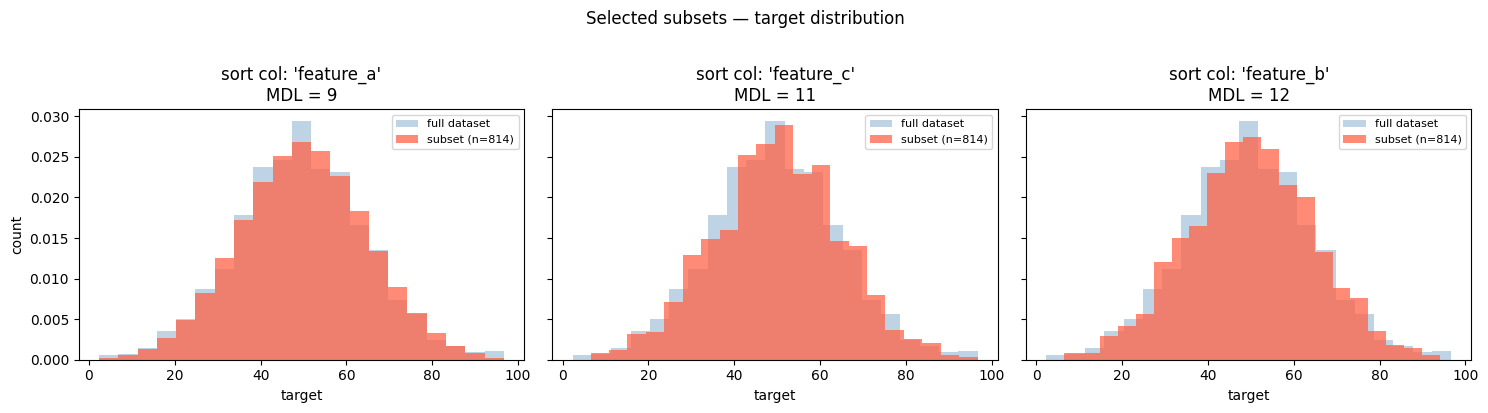

In [17]:
fig, axes = plt.subplots(1, len(subset_report), figsize=(5 * len(subset_report), 4), sharey=True)
if len(subset_report) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, subset_report.iterrows()):
    selected = df.loc[row["selected_indices"], "target"]
    ax.hist(df["target"], bins=n_bins, alpha=0.35, density=True, color="steelblue", label="full dataset")
    ax.hist(selected,     bins=n_bins, alpha=0.75, density=True, color="tomato",    label=f"subset (n={len(selected)})")
    ax.set_title(f"sort col: '{row['column']}'\nMDL = {row['mdl']}")
    ax.set_xlabel("target")
    ax.legend(fontsize=8)

axes[0].set_ylabel("count")
plt.suptitle("Selected subsets — target distribution", y=1.02)
plt.tight_layout()
plt.show()